<a href="https://colab.research.google.com/github/mdd214/CDS230-Lab8/blob/main/knn_glass_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hyunwoo Sun, Sungil Moon

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the Glass Identification dataset
from google.colab import files
from io import BytesIO

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(BytesIO(uploaded[filename]))

print(df.shape)
df.head()

print("Glass Identification Dataset")
print("Total samples:", df.shape[0])
print("Number of features:", df.shape[1] - 2)
print("Number of classes:", df['Type'].nunique())

print("\nGlass type distribution:")
print(df['Type'].value_counts().sort_index())

df.head()

Saving glass.csv to glass.csv
(214, 11)
Glass Identification Dataset
Total samples: 214
Number of features: 9
Number of classes: 6

Glass type distribution:
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


,Id,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,2,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,3,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,4,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,5,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


Average feature values by glass type:
         RI      Na     Mg     Al      Si      K      Ca     Ba     Fe
Type                                                                  
1     1.519  13.242  3.552  1.164  72.619  0.447   8.797  0.013  0.057
2     1.519  13.112  3.002  1.408  72.598  0.521   9.074  0.050  0.080
3     1.518  13.437  3.544  1.201  72.405  0.406   8.783  0.009  0.057
5     1.519  12.828  0.774  2.034  72.366  1.470  10.124  0.188  0.061
6     1.517  14.647  1.306  1.367  73.207  0.000   9.357  0.000  0.000
7     1.517  14.442  0.538  2.123  72.966  0.325   8.491  1.040  0.013


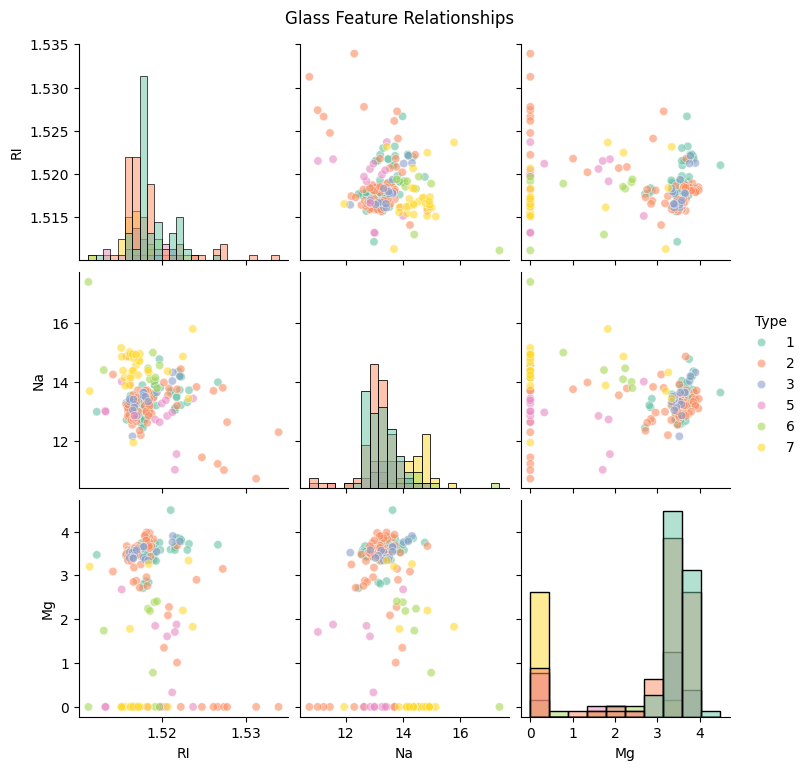

In [ ]:
# Compare average chemical composition by glass type
print("Average feature values by glass type:")
print(df.drop(columns='Id').groupby('Type').mean().round(3))

# Visualize relationships between features
plot_features = ['RI', 'Na', 'Mg', 'Type']

sns.pairplot(
    df[plot_features],
    hue='Type',
    palette='Set2',
    diag_kind='hist',
    plot_kws={'alpha': 0.6}
)

plt.suptitle('Glass Feature Relationships', y=1.02)
plt.show()

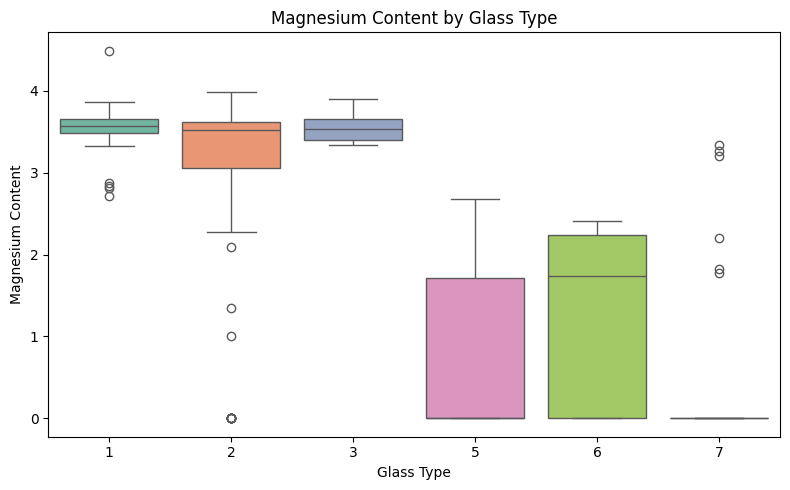

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Type',
    y='Mg',
    hue='Type',
    palette='Set2',
    legend=False
)

plt.xlabel('Glass Type')
plt.ylabel('Magnesium Content')
plt.title('Magnesium Content by Glass Type')
plt.tight_layout()
plt.show()

In [ ]:
# Separate features and target
X = df.drop(columns=['Id', 'Type'])
y = df['Type']

# Split into training and testing datasets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training samples: 171
Testing samples: 43


In [ ]:
knn = KNeighborsClassifier(n_neighbors=7)

# Train the model
knn.fit(X_train_scaled, y_train)

# Predict glass types
y_pred = knn.predict(X_test_scaled)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"KNN Accuracy (K=7): {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

KNN Accuracy (K=7): 69.77%

Classification Report:
              precision    recall  f1-score   support

           1       0.62      0.71      0.67        14
           2       0.69      0.73      0.71        15
           3       0.00      0.00      0.00         3
           5       0.75      1.00      0.86         3
           6       1.00      0.50      0.67         2
           7       0.83      0.83      0.83         6

    accuracy                           0.70        43
   macro avg       0.65      0.63      0.62        43
weighted avg       0.66      0.70      0.67        43



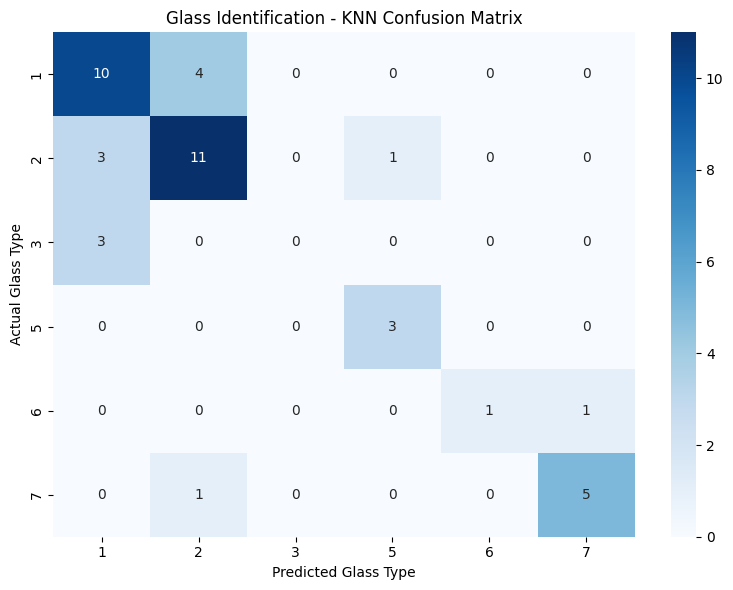

In [ ]:
# Confusion Matrix

glass_types = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=glass_types
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=glass_types,
    yticklabels=glass_types
)

plt.xlabel('Predicted Glass Type')
plt.ylabel('Actual Glass Type')
plt.title('Glass Identification - KNN Confusion Matrix')

plt.tight_layout()
plt.show()

Best K: 1
Best CV Accuracy: 67.80%


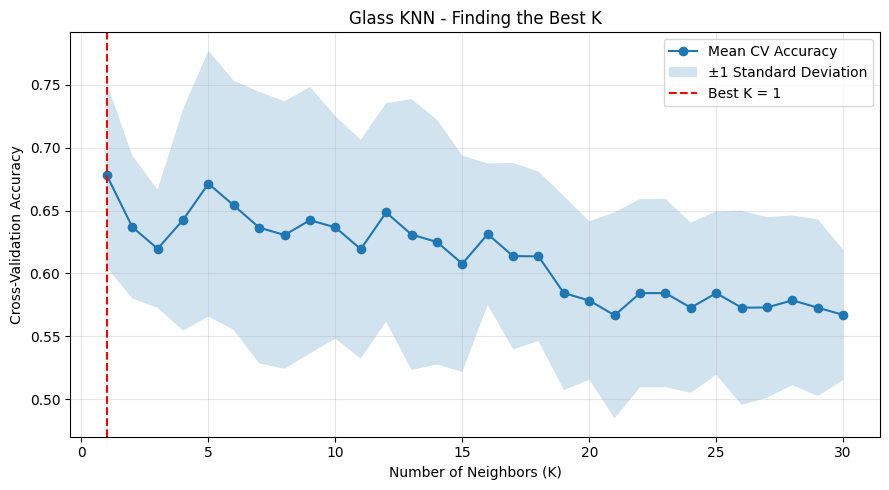

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

k_range = range(1, 31)
cv_means = []
cv_stds = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for k in k_range:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

cv_means = np.array(cv_means)
cv_stds = np.array(cv_stds)

best_k = list(k_range)[np.argmax(cv_means)]

print("Best K:", best_k)
print(f"Best CV Accuracy: {max(cv_means):.2%}")

# Visualize K vs Accuracy
plt.figure(figsize=(9, 5))

plt.plot(k_range, cv_means, marker='o', label='Mean CV Accuracy')

plt.fill_between(
    k_range,
    cv_means - cv_stds,
    cv_means + cv_stds,
    alpha=0.2,
    label='±1 Standard Deviation'
)

plt.axvline(best_k, color='red', linestyle='--', label=f'Best K = {best_k}')

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Cross-Validation Accuracy')
plt.title('Glass KNN - Finding the Best K')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
final_model = KNeighborsClassifier(n_neighbors=best_k)

final_model.fit(X_train_scaled, y_train)

final_predictions = final_model.predict(X_test_scaled)

final_accuracy = accuracy_score(y_test, final_predictions)

print(f"Initial Accuracy (K=7): {accuracy:.2%}")
print(f"Final Accuracy (K={best_k}): {final_accuracy:.2%}")

print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))


Initial Accuracy (K=7): 69.77%
Final Accuracy (K=1): 69.77%

Final Classification Report:
              precision    recall  f1-score   support

           1       0.80      0.57      0.67        14
           2       0.62      0.67      0.65        15
           3       0.40      0.67      0.50         3
           5       0.75      1.00      0.86         3
           6       0.50      0.50      0.50         2
           7       1.00      1.00      1.00         6

    accuracy                           0.70        43
   macro avg       0.68      0.73      0.69        43
weighted avg       0.72      0.70      0.70        43



In [ ]:
# Select three samples from the test dataset
new_glasses = X_test.iloc[:3]

# Standardize the samples
new_glasses_scaled = scaler.transform(new_glasses)

# Predict glass types
predictions = final_model.predict(new_glasses_scaled)
probabilities = final_model.predict_proba(new_glasses_scaled)

print("Glass Classification Results\n")

for i in range(len(new_glasses)):
    print(f"Glass Sample {i+1}")
    print("Predicted Type:", predictions[i])
    print("Actual Type:", y_test.iloc[i])
    print("Neighbor Vote Proportions:")

    for glass_type, prob in zip(final_model.classes_, probabilities[i]):
        print(f"  Type {glass_type}: {prob:.1%}")

    print("-" * 35)

Glass Classification Results

Glass Sample 1
Predicted Type: 7
Actual Type: 7
Neighbor Vote Proportions:
  Type 1: 0.0%
  Type 2: 0.0%
  Type 3: 0.0%
  Type 5: 0.0%
  Type 6: 0.0%
  Type 7: 100.0%
-----------------------------------
Glass Sample 2
Predicted Type: 5
Actual Type: 5
Neighbor Vote Proportions:
  Type 1: 0.0%
  Type 2: 0.0%
  Type 3: 0.0%
  Type 5: 100.0%
  Type 6: 0.0%
  Type 7: 0.0%
-----------------------------------
Glass Sample 3
Predicted Type: 2
Actual Type: 2
Neighbor Vote Proportions:
  Type 1: 0.0%
  Type 2: 100.0%
  Type 3: 0.0%
  Type 5: 0.0%
  Type 6: 0.0%
  Type 7: 0.0%
-----------------------------------


## Summary
The dataset contains 214 glass samples divided into six different types. I used 80% of the data to train the model and the remaining 20% to test its performance. Initial model used seven nearest neighbors (K=7) and achieved an accuracy of 69.77%, correctly identifying 30 out of 43 glass samples.

The model performed relatively well when identifying glass Types 5 and 7. However, it had difficulty identifying Type 3, which may be related to the small number of samples in that category. I also used 5-fold cross-validation to find the best number of neighbors and evaluated the final model using the test dataset.

Source: https://archive.ics.uci.edu/dataset/42/glass+identification